In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors
import seaborn as sns
import torch
from src.model import Model

mpl.rcParams['text.usetex'] = True
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "Times New Roman"

fontsize= 27

colors = ["tab:red", "tab:blue"]

In [3]:

def read_dataset(file_path):
    sequences = []
    # Read the dataset
    with open(file_path, 'r') as f:
        f.readline()
        for line in f:
            seq = line.strip().split('\t')[0]
            sequences.append(seq)
    print(f"Total sequences: {len(sequences)}")
    return sequences

In [4]:
# Read the model
'''
modelname="model_k=4_d=256_negperpos=200_maxseq=100000_epoch=100_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_main_cpu_checkpoint.model.epoch_20.checkpoint"
model_path = f"../notebooks/models/{modelname}"
kwargs, model_state_dict = torch.load(model_path, map_location=torch.device("cpu"))
model = Model(**kwargs)
model.load_state_dict(model_state_dict)
model.eval()

dataset_names = ["reference", "plant", "marine"]
versions = [5, 6]
for dataset in dataset_names:
    for version in versions:
        dataset_path = f"../dataset/{dataset}_binning_{version}.tsv"
        sequences = read_dataset(dataset_path)
        print(f"{dataset} v{version}: {len(sequences)} sequences")

        # Get the embeddings and covariances
        embs, cov = model.seq2emb(sequences)
        np.savez(file=f"../notebooks/std_distribution/{dataset}_binning_{version}.npz", embs=embs, cov=cov)

'''

'\nmodelname="model_k=4_d=256_negperpos=200_maxseq=100000_epoch=100_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed=1_main_cpu_checkpoint.model.epoch_20.checkpoint"\nmodel_path = f"../notebooks/models/{modelname}"\nkwargs, model_state_dict = torch.load(model_path, map_location=torch.device("cpu"))\nmodel = Model(**kwargs)\nmodel.load_state_dict(model_state_dict)\nmodel.eval()\n\ndataset_names = ["reference", "plant", "marine"]\nversions = [5, 6]\nfor dataset in dataset_names:\n    for version in versions:\n        dataset_path = f"../dataset/{dataset}_binning_{version}.tsv"\n        sequences = read_dataset(dataset_path)\n        print(f"{dataset} v{version}: {len(sequences)} sequences")\n\n        # Get the embeddings and covariances\n        embs, cov = model.seq2emb(sequences)\n        np.savez(file=f"../notebooks/std_distribution/{dataset}_binning_{version}.npz", embs=embs, cov=cov)\n\n'

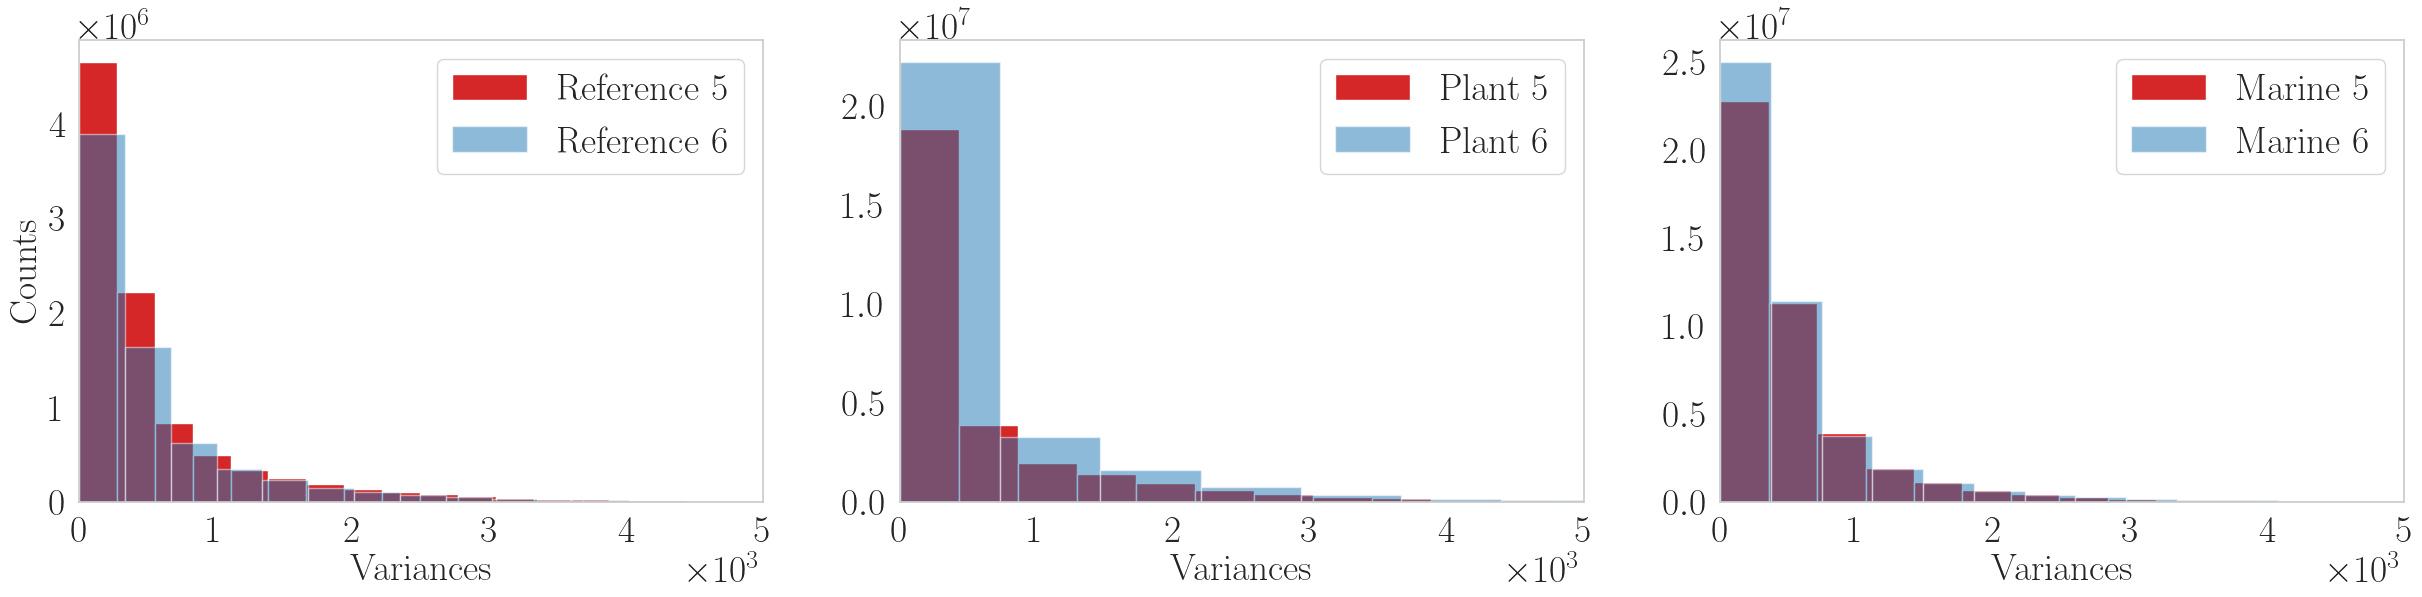

In [5]:
from matplotlib.ticker import ScalarFormatter

reference5_cov = np.load(file=f"../notebooks/std_distribution/reference_binning_5.npz")['cov'].reshape(-1)
reference6_cov = np.load(file=f"../notebooks/std_distribution/reference_binning_6.npz")['cov'].reshape(-1)

plant5_cov = np.load(file=f"../notebooks/std_distribution/plant_binning_5.npz")['cov'].reshape(-1)
plant6_cov = np.load(file=f"../notebooks/std_distribution/plant_binning_6.npz")['cov'].reshape(-1)

marine5_cov = np.load(file=f"../notebooks/std_distribution/marine_binning_5.npz")['cov'].reshape(-1)
marine6_cov = np.load(file=f"../notebooks/std_distribution/marine_binning_6.npz")['cov'].reshape(-1)

# Plot the histograms side by side
fig, axes = plt.subplots(1, 3, figsize=(30, 6))

axes[0].hist(reference5_cov, color=colors[0], bins=100, alpha=1, label="Reference 5")
axes[0].hist(reference6_cov, color=colors[1], bins=100, alpha=0.5, label="Reference 6")
axes[0].set_xlabel('Variances', fontsize=fontsize)
axes[0].set_ylabel('Counts', fontsize=fontsize)
axes[0].legend(fontsize=fontsize)
axes[0].set_xlim(0, 5000) # Set the x-axis range to [0, 5000]
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))
axes[0].xaxis.get_offset_text().set_fontsize(fontsize)
axes[0].yaxis.get_offset_text().set_fontsize(fontsize)
axes[0].xaxis.set_major_formatter(formatter)
axes[0].grid(False)
axes[0].tick_params(axis='x', labelsize=fontsize)
axes[0].tick_params(axis='y', labelsize=fontsize)

axes[1].hist(plant5_cov, color=colors[0], bins=100, alpha=1, label="Plant 5")
axes[1].hist(plant6_cov, color=colors[1], bins=100, alpha=0.5, label="Plant 6")
axes[1].set_xlabel('Variances', fontsize=fontsize)
# axes[1].set_ylabel('Counts', fontsize=fontsize)
axes[1].legend(fontsize=fontsize)
axes[1].set_xlim(0, 5000) # Set the x-axis range to [0, 5000]
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))
axes[1].xaxis.get_offset_text().set_fontsize(fontsize)
axes[1].yaxis.get_offset_text().set_fontsize(fontsize)
axes[1].xaxis.set_major_formatter(formatter)
axes[1].grid(False)
axes[1].tick_params(axis='x', labelsize=fontsize)
axes[1].tick_params(axis='y', labelsize=fontsize)

axes[2].hist(marine5_cov, color=colors[0], bins=100, alpha=1, label="Marine 5")
axes[2].hist(marine6_cov, color=colors[1], bins=100, alpha=0.5, label="Marine 6")
axes[2].set_xlabel('Variances', fontsize=fontsize)
# axes[2].set_ylabel('Counts', fontsize=fontsize)
axes[2].legend(fontsize=fontsize)
axes[2].set_xlim(0, 5000) # Set the x-axis range to [0, 5000]
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))
axes[2].xaxis.get_offset_text().set_fontsize(fontsize)
axes[2].yaxis.get_offset_text().set_fontsize(fontsize)
axes[2].xaxis.set_major_formatter(formatter)
axes[2].grid(False)
axes[2].tick_params(axis='x', labelsize=fontsize)
axes[2].tick_params(axis='y', labelsize=fontsize)

plt.savefig(f"../paper/figures/cov_histogram_all_datasets.pdf", bbox_inches='tight')
# plt.show()

In [6]:

# dataset_name = "marine"
#
# # Flatten the covariance matrix and plot histograms
# plt.figure(figsize=(10, 6))
# for version in [5, 6]:
#     dataset_path = f"../dataset/{dataset_name}_binning_{version}.tsv"
#     sequences = read_dataset(dataset_path)
#     # Get the embeddings and covariances
#     embs, cov = model.seq2emb(sequences)
#     cov_flat = cov.reshape(-1)
#     print(f"Embeddings shape: {embs.shape}, Covariances shape: {cov.shape}")
#     plt.hist(cov_flat, bins=100, color=colors[version-5], alpha=0.99 if version == 5 else 0.5, log=True, label=f"{dataset_name} {version}")
#     # plt.title('Histogram of Flattened Covariance Matrix', fontsize=fontsize) histtype='step',
# plt.xlabel('Variances', fontsize=fontsize)
# plt.ylabel('Counts  (in log scale)', fontsize=fontsize)
# plt.grid(False)
# plt.legend(fontsize=fontsize)
# plt.xticks(fontsize=fontsize)
# plt.yticks(fontsize=fontsize)
# # plt.show()
# plt.savefig(f"../paper/figures/cov_histogram_{dataset_name}.pdf", bbox_inches='tight')

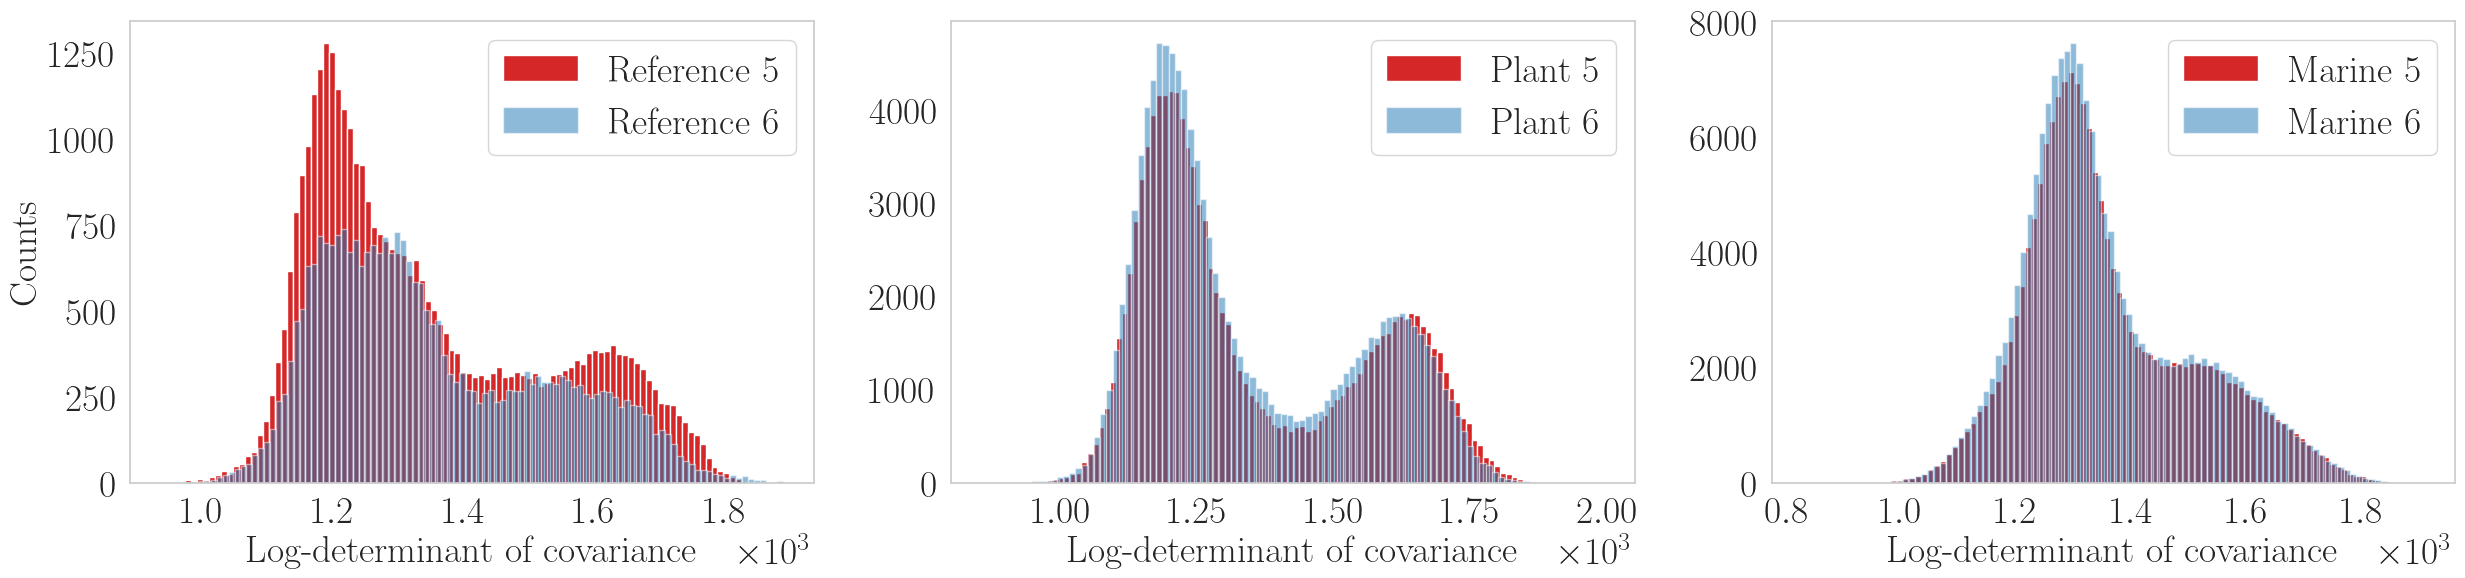

In [7]:
reference5_cov = np.load(file=f"../notebooks/std_distribution/reference_binning_5.npz")['cov']
reference6_cov = np.load(file=f"../notebooks/std_distribution/reference_binning_6.npz")['cov']
reference5_cov = np.log(reference5_cov + 1).sum(axis=-1)
reference6_cov = np.log(reference6_cov + 1).sum(axis=-1)

plant5_cov = np.load(file=f"../notebooks/std_distribution/plant_binning_5.npz")['cov']
plant6_cov = np.load(file=f"../notebooks/std_distribution/plant_binning_6.npz")['cov']
plant5_cov = np.log(plant5_cov + 1).sum(axis=-1)
plant6_cov = np.log(plant6_cov + 1).sum(axis=-1)

marine5_cov = np.load(file=f"../notebooks/std_distribution/marine_binning_5.npz")['cov']
marine6_cov = np.load(file=f"../notebooks/std_distribution/marine_binning_6.npz")['cov']
marine5_cov = np.log(marine5_cov + 1).sum(axis=-1)
marine6_cov = np.log(marine6_cov + 1).sum(axis=-1)

# Plot the histograms side by side
fig, axes = plt.subplots(1, 3, figsize=(30, 6))


axes[0].hist(reference5_cov, color=colors[0], bins=100, alpha=1, label="Reference 5")
axes[0].hist(reference6_cov, color=colors[1], bins=100, alpha=0.5, label="Reference 6")
axes[0].set_xlabel('Log-determinant of covariance', fontsize=fontsize)
axes[0].set_ylabel('Counts', fontsize=fontsize)
axes[0].legend(fontsize=fontsize)
# axes[0].set_xlim(0, 5000) # Set the x-axis range to [0, 5000]
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))
axes[0].xaxis.get_offset_text().set_fontsize(fontsize)
axes[0].yaxis.get_offset_text().set_fontsize(fontsize)
axes[0].xaxis.set_major_formatter(formatter)
axes[0].grid(False)
axes[0].tick_params(axis='x', labelsize=fontsize)
axes[0].tick_params(axis='y', labelsize=fontsize)
# axes[0].set_xlim(1, 2)


axes[1].hist(plant5_cov, color=colors[0], bins=100, alpha=1, label="Plant 5")
axes[1].hist(plant6_cov, color=colors[1], bins=100, alpha=0.5, label="Plant 6")
axes[1].set_xlabel('Log-determinant of covariance', fontsize=fontsize)
# axes[1].set_ylabel('Counts', fontsize=fontsize)
axes[1].legend(fontsize=fontsize)
# axes[1].set_xlim(0, 5000) # Set the x-axis range to [0, 5000]
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))
axes[1].xaxis.get_offset_text().set_fontsize(fontsize)
axes[1].yaxis.get_offset_text().set_fontsize(fontsize)
axes[1].xaxis.set_major_formatter(formatter)
axes[1].grid(False)
axes[1].tick_params(axis='x', labelsize=fontsize)
axes[1].tick_params(axis='y', labelsize=fontsize)


axes[2].hist(marine5_cov, color=colors[0], bins=100, alpha=1, label="Marine 5")
axes[2].hist(marine6_cov, color=colors[1], bins=100, alpha=0.5, label="Marine 6")
axes[2].set_xlabel('Log-determinant of covariance', fontsize=fontsize)
# axes[2].set_ylabel('Counts', fontsize=fontsize)
axes[2].legend(fontsize=fontsize)
# axes[2].set_xlim(1000, 2000) # Set the x-axis range to [0, 5000]
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))
axes[2].xaxis.get_offset_text().set_fontsize(fontsize)
axes[2].yaxis.get_offset_text().set_fontsize(fontsize)
axes[2].xaxis.set_major_formatter(formatter)
axes[2].grid(False)
axes[2].tick_params(axis='x', labelsize=fontsize)
axes[2].tick_params(axis='y', labelsize=fontsize)

plt.savefig(f"../paper/figures/determinant_histogram_all_datasets.pdf", bbox_inches='tight')


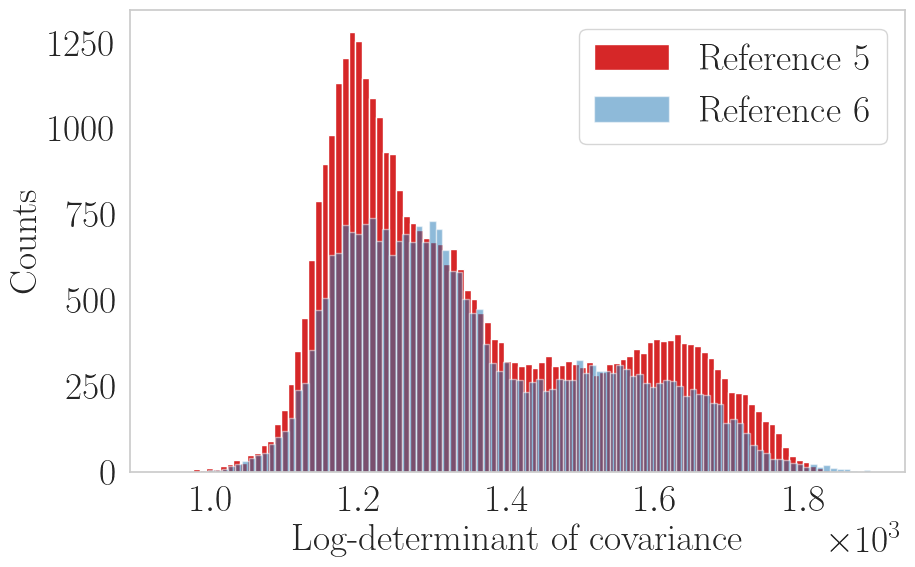

In [8]:
# Single plot

reference5_cov = np.load(file=f"../notebooks/std_distribution/reference_binning_5.npz")['cov']
reference6_cov = np.load(file=f"../notebooks/std_distribution/reference_binning_6.npz")['cov']
reference5_cov = np.log(reference5_cov + 1).sum(axis=-1)
reference6_cov = np.log(reference6_cov + 1).sum(axis=-1)

plt.figure(figsize=(10, 6))
plt.hist(reference5_cov, color=colors[0], bins=100, alpha=1, label="Reference 5")
plt.hist(reference6_cov, color=colors[1], bins=100, alpha=0.5, label="Reference 6")
plt.xlabel('Log-determinant of covariance', fontsize=fontsize)
plt.ylabel('Counts', fontsize=fontsize)
plt.legend(fontsize=fontsize)
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))
plt.gca().xaxis.get_offset_text().set_fontsize(fontsize)
plt.gca().yaxis.get_offset_text().set_fontsize(fontsize)
plt.gca().xaxis.set_major_formatter(formatter)
plt.grid(False)
plt.tick_params(axis='x', labelsize=fontsize)
plt.tick_params(axis='y', labelsize=fontsize)
plt.savefig(f"../paper/figures/determinant_histogram_reference5_6.pdf", bbox_inches='tight')
# plt.show()